<a href="https://colab.research.google.com/github/Uriel1201/Hello-Notebooks/blob/main/rust.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/Uriel1201/hello-pyplots.git
!git clone https://github.com/Uriel1201/hello_rust.git
!curl --proto '=https' --tlsv1.2 -sSf https://sh.rustup.rs | sh -s -- -y
import os
os.environ["PATH"] += ":" + os.path.expanduser("~/.cargo/bin")
%cd hello_rust

Cloning into 'hello-pyplots'...
remote: Enumerating objects: 25, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (24/24), done.
remote: Total 25 (delta 13), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (25/25), 8.80 KiB | 2.20 MiB/s, done.
Resolving deltas: 100% (13/13), done.
Cloning into 'hello_rust'...
remote: Enumerating objects: 361, done.
remote: Counting objects: 100% (361/361), done.
remote: Compressing objects: 100% (333/333), done.
remote: Total 361 (delta 154), reused 16 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (361/361), 115.45 KiB | 1.63 MiB/s, done.
Resolving deltas: 100% (154/154), done.
info: downloading installer
info: profile set to default
info: default host tuple is x86_64-unknown-linux-gnu
info: syncing channel updates for stable-x86_64-unknown-linux-gnu
info: latest update on 2026-10-15 for version 1.99.1 (58cf8f9c3 2026-10-13)
info: downloading 6 components
      rustfmt installed       

In [2]:
from IPython.display import Image, display

## Birthday
Write a program birthday.rs that takes two integer command-line arguments n
and trials and performs the following experiment, trials times:

 -  Choose a birthday for the next person, uniformly at random between 0 and n−1.
 - Have that person enter the room.
 - If that person shares a birthday with someone else in the room, stop; otherwise repeat.

 In each experiment, count the number of people that enter the room.
 Print a table that summarizes the results (the count i, the number of times that
 exactly i people enter the room, and the fraction of times that i or fewer people enter the room)
 for each possible value of i from 1 until the fraction reaches (or exceeds) 50%.

### Main

```rust
fn main() -> ExitCode {
    let args: Vec<String> = std::env::args().skip(1).collect();
    let n: usize = match args[0].parse() {
        Ok(n) => n,
        Err(_) => {
            eprintln!("Error: was expected an Integer");
            return ExitCode::FAILURE;
        }
    };
    let trials: usize = match args[1].parse() {
        Ok(trials) => trials,
        Err(_) => {
            eprintln!("Error: was expected an Integer");
            return ExitCode::FAILURE;
        }
    };
    let mut s = vec![0u64; n + 2];
    let mut rng = rand::rng();
    for _ in 0..trials {
        let mut birthday = vec![false; n];
        let mut count = 0;
        for _ in 0..n + 1 {
            let p = rng.random_range(0..n);
            count += 1;
            if birthday[p] {
                break;
            }
            birthday[p] = true;
        }
        s[count] += 1;
    }
    let mut f = 0.0;
    for (k, count) in s.into_iter().enumerate() {
        f += count as f64 / trials as f64;
        println!("{}  {}  {}", k, count, f);
        if f >= 0.5 {
            break;
        }
    }
    ExitCode::SUCCESS
}
```

In [4]:
!cargo build --release --bin birthday

    Finished `release` profile [optimized] target(s) in 0.02s


In [6]:
!./target/release/birthday 365 1000000 | env -u MPLBACKEND uv run --script /content/hello-pyplots/plot_birthday.py

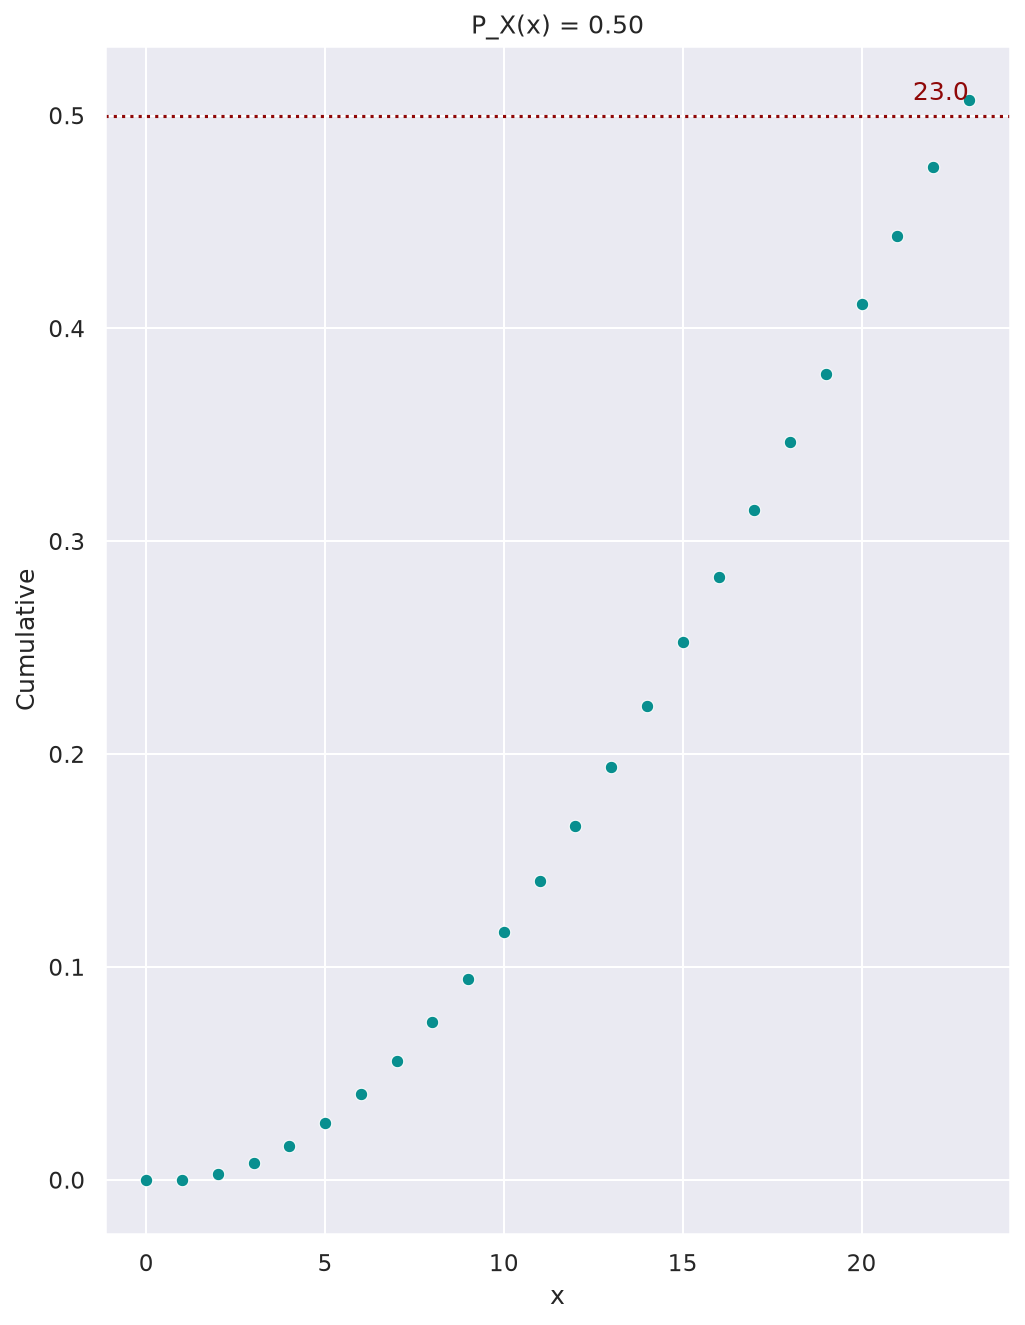

In [7]:
display(Image('images/birthday.png'))

# Discrete Distribution

## Main
Write a program discrete_distribution.rs that takes an integer command-line
  argument m, followed by a sequence of positive integer command-line arguments a1,a2,…,an
  and prints m random indices (separated by whitespace), choosing each index i
  with probability proportional to ai.

```rust
fn main() -> ExitCode {
    let mut args = std::env::args().skip(1);
    let mut values: Vec<u64> = Vec::new();
    while let Some(nextarg) = args.next() {
        let value: u64 = match nextarg.parse() {
            Ok(v) => v,
            Err(_) => {
                eprintln!("Error: was expected an Integer");
                return ExitCode::FAILURE;
            }
        };
        values.push(value);
    }
    if values.len() < 2 {
       eprintln!("Usage: m a1 a2 ... an");
       return ExitCode::FAILURE;
    }
    let m: u64 = values.remove(0);
    let mut s: Vec<u64> = Vec::with_capacity(values.len() + 1);
    s.push(0);
    let mut cumulative: u64 = 0;
    for value in values {
        cumulative += value;
        s.push(cumulative);
    }
    let mut rng = rand::rng();
    for _ in 0..m {
        let p = rng.random_range(0..cumulative);
        let j = s.partition_point(|&x| x <= p);
        print!("{j}  ");
    }
    println!();
    ExitCode::SUCCESS
}
```

In [8]:
!cargo build --release --bin discrete_distribution

   Compiling hello_rust v0.1.0 (/content/hello_rust)
    Finished `release` profile [optimized] target(s) in 0.54s


In [10]:
!./target/release/discrete_distribution 1000000 10 10 12 80 80 90 700 350 | env -u MPLBACKEND uv run --script /content/hello-pyplots/plot_dist.py

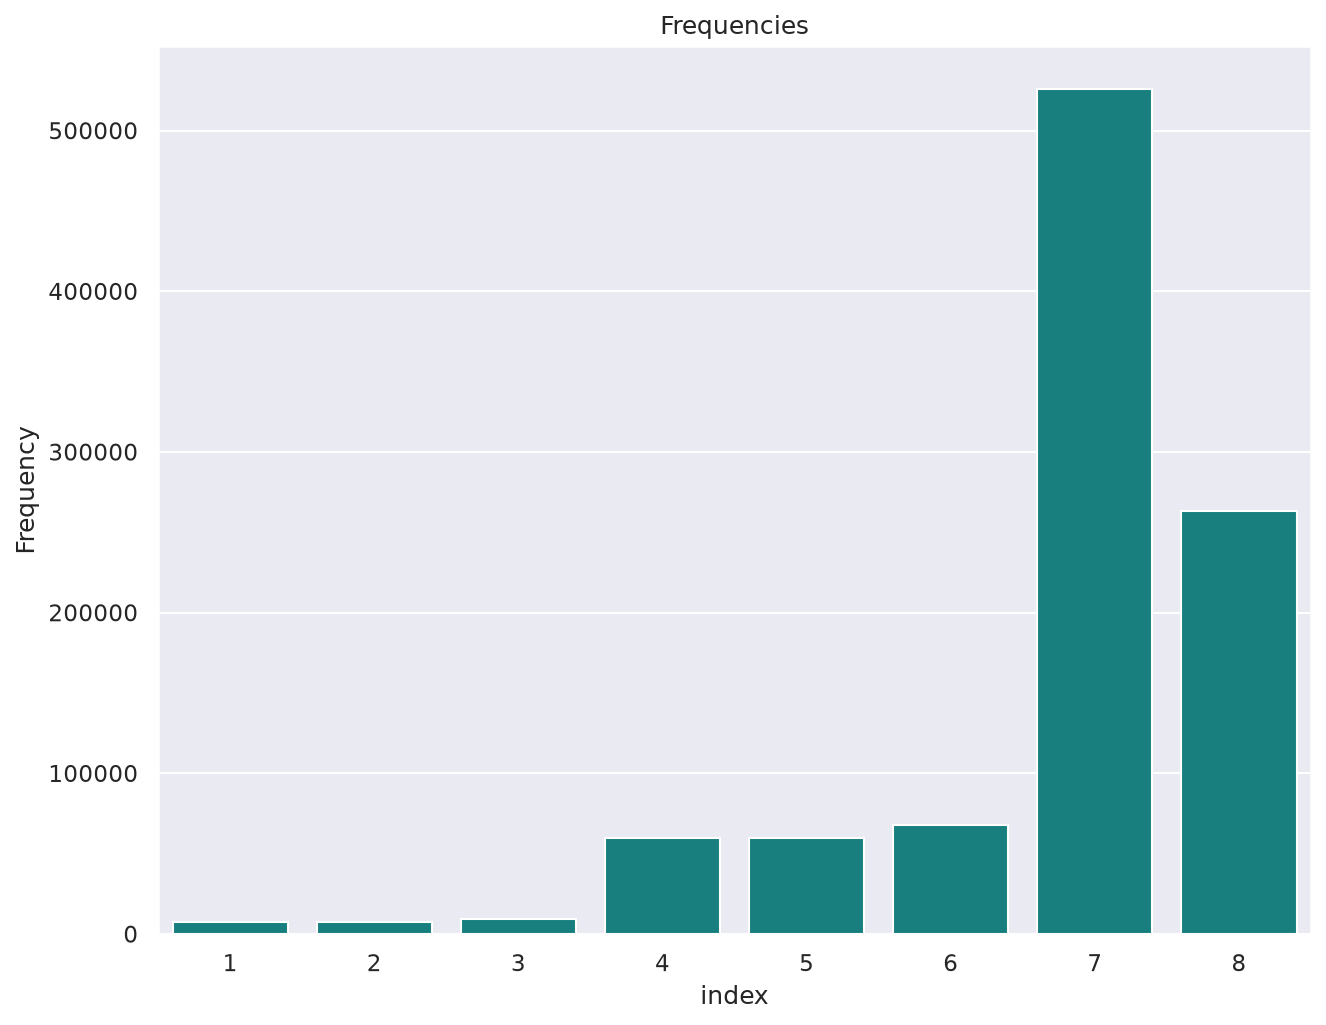

In [11]:
display(Image('images/discret_distribution.png'))